In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Detect project root folder

current_dir = Path.cwd()

if (current_dir / "data").exists():
    BASE_DIR = current_dir
elif (current_dir.parent / "data").exists():
    BASE_DIR = current_dir.parent
else:
    raise FileNotFoundError("Project data folder not found.")

DATA_PATH = BASE_DIR / "data" / "Palo Alto Networks.csv"
MODEL_DIR = BASE_DIR / "models"
REPORT_DIR = BASE_DIR / "reports"

MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

print("Project folder:", BASE_DIR)
print("Dataset path:", DATA_PATH)

Project folder: c:\Users\91785\OneDrive\Desktop\employee-attrition-prediction
Dataset path: c:\Users\91785\OneDrive\Desktop\employee-attrition-prediction\data\Palo Alto Networks.csv


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   str  
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   str  
 14  JobSatisfaction           1470

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,0.161224,802.485714,9.192517,2.912925,2.721769,65.891156,2.729932,2.063946,2.728571,...,3.153741,2.712245,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,0.367863,403.509100,8.106864,1.024165,1.093082,20.329428,0.711561,1.106940,1.102846,...,0.360824,1.081209,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,0.000000,102.000000,1.000000,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,...,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,0.000000,465.000000,2.000000,2.000000,2.000000,48.000000,2.000000,1.000000,2.000000,...,3.000000,2.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,0.000000,802.000000,7.000000,3.000000,3.000000,66.000000,3.000000,2.000000,3.000000,...,3.000000,3.000000,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,0.000000,1157.000000,14.000000,4.000000,4.000000,83.750000,3.000000,3.000000,4.000000,...,3.000000,4.000000,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1.000000,1499.000000,29.000000,5.000000,4.000000,100.000000,4.000000,5.000000,4.000000,...,4.000000,4.000000,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


Attrition Count:
Attrition
0    1233
1     237
Name: count, dtype: int64

Attrition Percentage:
Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64


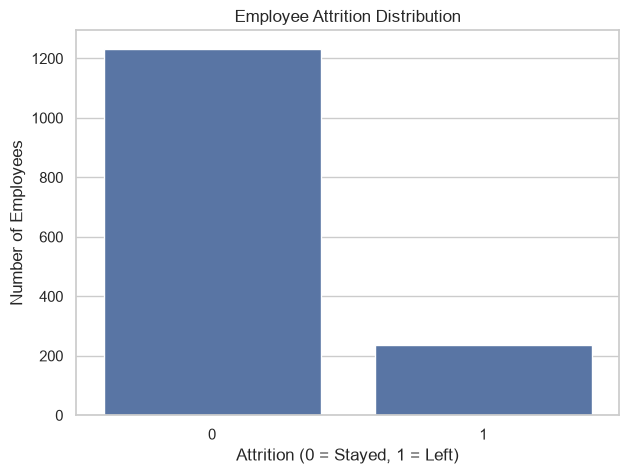

In [5]:
print("Attrition Count:")
print(df["Attrition"].value_counts())

print("\nAttrition Percentage:")
print(df["Attrition"].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Employees")
plt.show()

Age Statistics:


count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

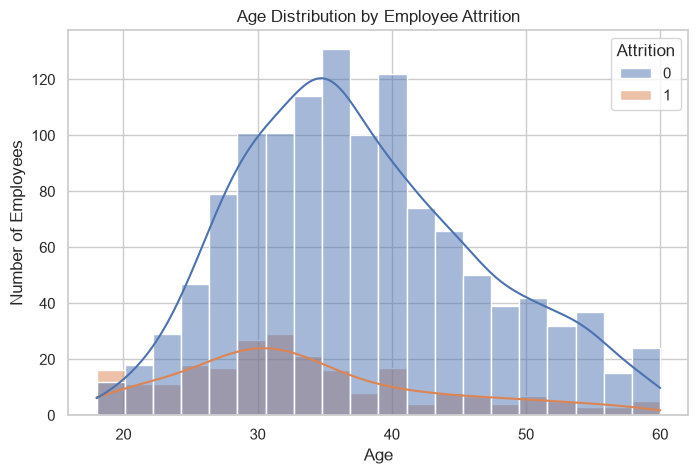

AgeGroup
18-25    35.772358
26-35    19.141914
36-45     9.188034
46-55    11.504425
56-65    17.021277
Name: Attrition, dtype: float64


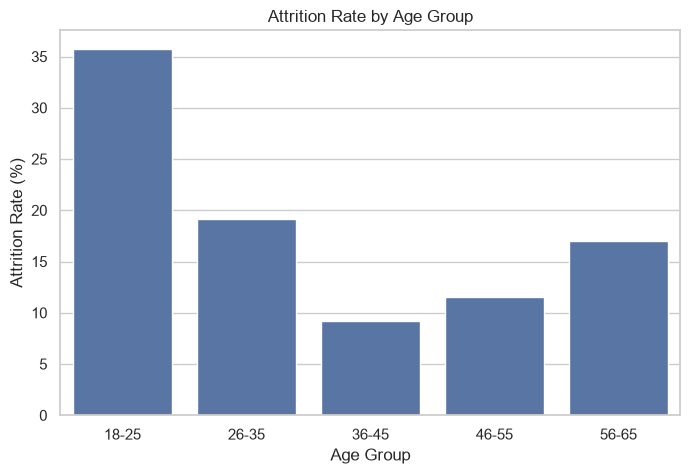

In [6]:
print("Age Statistics:")
display(df["Age"].describe())

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Attrition",
    bins=20,
    kde=True
)

plt.title("Age Distribution by Employee Attrition")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.show()


# Age Group-wise Attrition Rate

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

age_attrition = df.groupby(
    "AgeGroup", observed=False
)["Attrition"].mean() * 100

print(age_attrition)

plt.figure(figsize=(8, 5))
sns.barplot(x=age_attrition.index, y=age_attrition.values)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.show()

Department-wise Attrition Rate:


Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition, dtype: float64

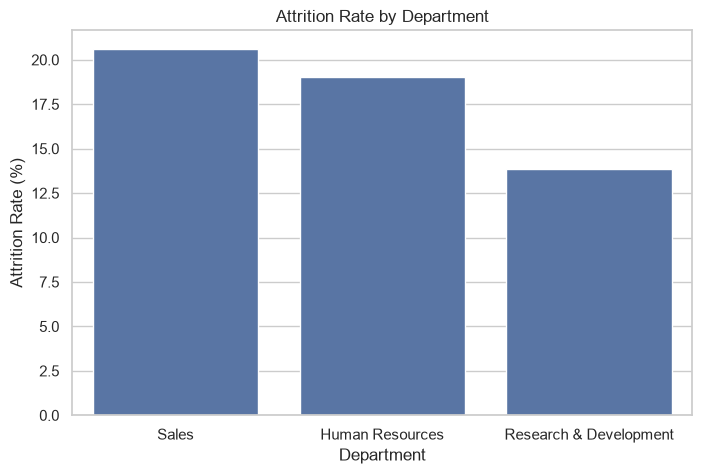

Job Role-wise Attrition Rate:


JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64

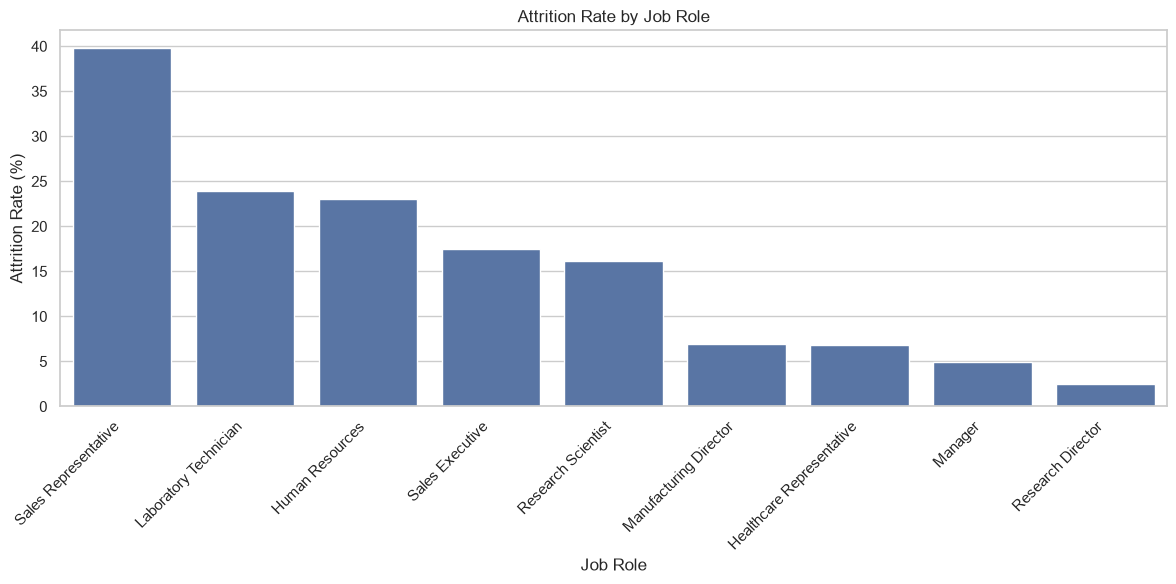

In [7]:
# Department-wise Attrition

department_attrition = (
    df.groupby("Department")["Attrition"].mean() * 100
).sort_values(ascending=False)

print("Department-wise Attrition Rate:")
display(department_attrition)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=department_attrition.index,
    y=department_attrition.values
)

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.show()


# Job Role-wise Attrition

role_attrition = (
    df.groupby("JobRole")["Attrition"].mean() * 100
).sort_values(ascending=False)

print("Job Role-wise Attrition Rate:")
display(role_attrition)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=role_attrition.index,
    y=role_attrition.values
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Overtime-wise Attrition Percentage:


Attrition,0,1
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


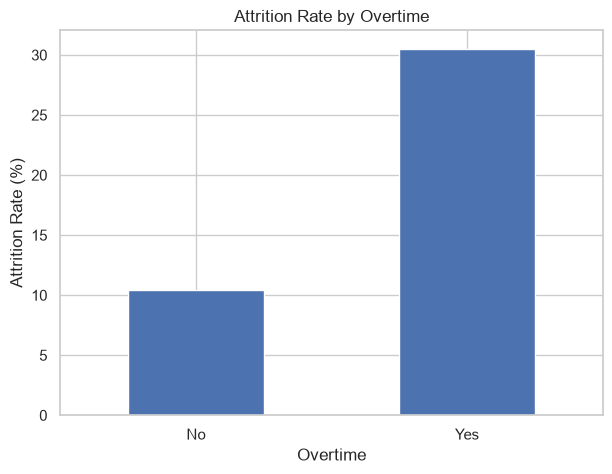

Job Satisfaction-wise Attrition:


Attrition,0,1
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


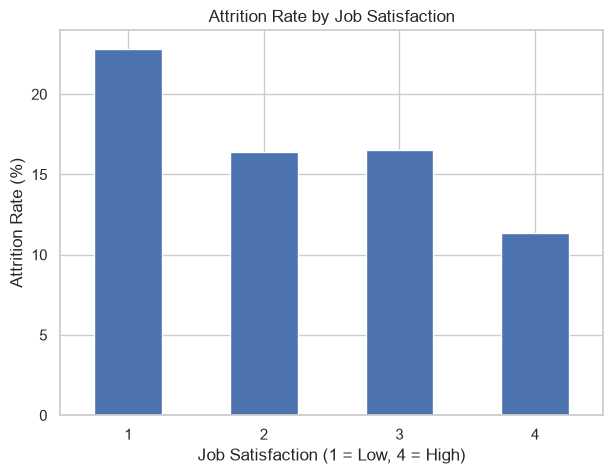

In [8]:
# Overtime Analysis

overtime_attrition = (
    pd.crosstab(
        df["OverTime"],
        df["Attrition"],
        normalize="index"
    ) * 100
)

print("Overtime-wise Attrition Percentage:")
display(overtime_attrition)

overtime_attrition[1].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.show()


# Job Satisfaction Analysis

satisfaction_attrition = (
    pd.crosstab(
        df["JobSatisfaction"],
        df["Attrition"],
        normalize="index"
    ) * 100
)

print("Job Satisfaction-wise Attrition:")
display(satisfaction_attrition)

satisfaction_attrition[1].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [9]:
# Create a separate cleaned dataset

processed_df = df.copy()

# Remove duplicate records
processed_df = processed_df.drop_duplicates()

# Fill missing numerical values with median
numerical_columns = processed_df.select_dtypes(
    include=["number"]
).columns

for col in numerical_columns:
    processed_df[col] = processed_df[col].fillna(
        processed_df[col].median()
    )

# Fill missing categorical values with mode
categorical_columns = processed_df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    if processed_df[col].isnull().any():
        processed_df[col] = processed_df[col].fillna(
            processed_df[col].mode()[0]
        )

print("Data cleaning completed!")
print("New Dataset Shape:", processed_df.shape)
print("Total Missing Values:", processed_df.isnull().sum().sum())

processed_df.to_csv(
    BASE_DIR / "data" / "processed_data.csv",
    index=False
)

Data cleaning completed!
New Dataset Shape: (1470, 32)
Total Missing Values: 0


In [10]:
model_df = processed_df.copy()

# Income compared to total work experience
model_df["IncomeExperienceRatio"] = (
    model_df["MonthlyIncome"] /
    (model_df["TotalWorkingYears"] + 1)
)

# Promotion delay indicator
model_df["PromotionDelay"] = (
    model_df["YearsSinceLastPromotion"] >= 3
).astype(int)

# Employee engagement score
engagement_columns = [
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance"
]

model_df["EngagementScore"] = (
    model_df[engagement_columns].mean(axis=1)
)

# Workload stress indicator
model_df["WorkloadStress"] = (
    (model_df["OverTime"] == "Yes") &
    (model_df["WorkLifeBalance"] <= 2)
).astype(int)

# Career stagnation indicator
model_df["CareerStagnation"] = (
    (model_df["YearsSinceLastPromotion"] >= 3) &
    (model_df["YearsInCurrentRole"] >= 3)
).astype(int)

print("Feature engineering completed!")

display(
    model_df[
        [
            "IncomeExperienceRatio",
            "PromotionDelay",
            "EngagementScore",
            "WorkloadStress",
            "CareerStagnation"
        ]
    ].head()
)

model_df.to_csv(
    BASE_DIR / "data" / "model_data.csv",
    index=False
)

Feature engineering completed!


,IncomeExperienceRatio,PromotionDelay,EngagementScore,WorkloadStress,CareerStagnation
0,665.888889,0,2.2,1,0
1,466.363636,0,2.8,0,0
2,261.250000,0,2.8,0,0
3,323.222222,1,3.2,0,1
4,495.428571,0,2.6,0,0


In [11]:
# Separate features and target

columns_to_drop = [
    "Attrition",
    "Gender",
    "MaritalStatus",
    "AgeGroup"
]

X = model_df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

y = model_df["Attrition"].astype(int)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (1470, 33)
Target Shape: (1470,)

Target Distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Attrition Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Attrition Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (1176, 33)
Testing Data: (294, 33)

Training Attrition Distribution:
Attrition
0    0.838435
1    0.161565
Name: proportion, dtype: float64

Testing Attrition Distribution:
Attrition
0    0.840136
1    0.159864
Name: proportion, dtype: float64


In [13]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
results = []

for model_name, classifier in models.items():

    print(f"\nTraining {model_name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    # Balance class weights for Gradient Boosting
    if model_name == "Gradient Boosting":
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        pipeline.fit(
            X_train,
            y_train,
            classifier__sample_weight=sample_weights
        )
    else:
        pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)
    y_probability = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_probability)
    })

    trained_models[model_name] = pipeline

    print(f"{model_name} training completed!")

print("\nAll models trained successfully!")


Training Logistic Regression...
Logistic Regression training completed!

Training Random Forest...
Random Forest training completed!

Training Gradient Boosting...
Gradient Boosting training completed!

All models trained successfully!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.758503,0.360465,0.659574,0.466165,0.780687
1,Random Forest,0.826531,0.375000,0.127660,0.190476,0.765957
2,Gradient Boosting,0.778912,0.359375,0.489362,0.414414,0.747782


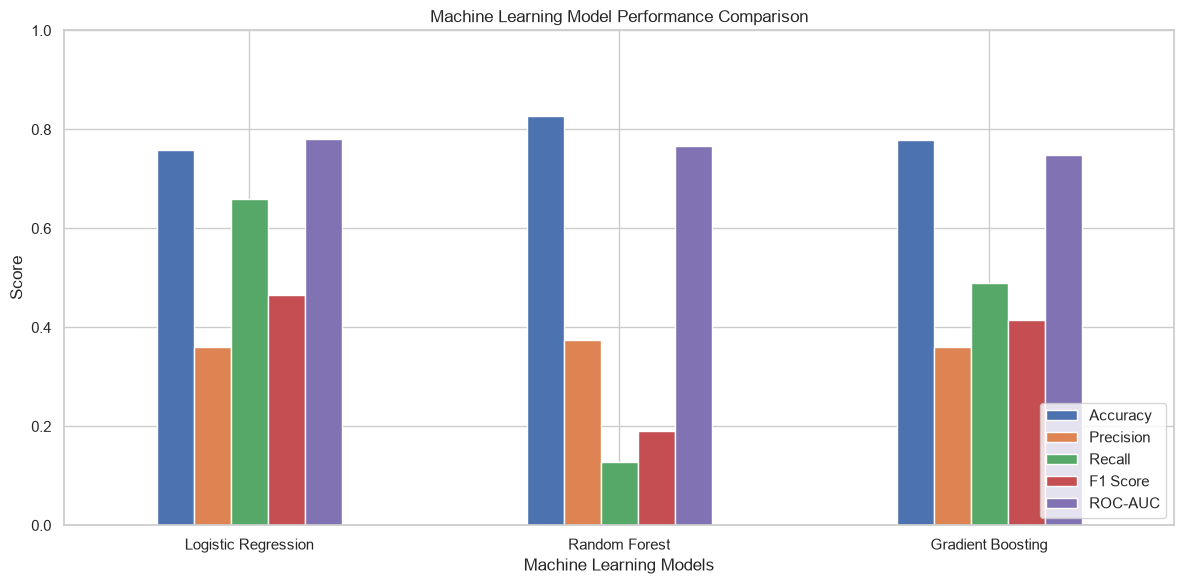

In [15]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df)

# Save model comparison report

results_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

# Visualize model performance

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.84       247
        Left       0.36      0.66      0.47        47

    accuracy                           0.76       294
   macro avg       0.64      0.72      0.66       294
weighted avg       0.83      0.76      0.78       294



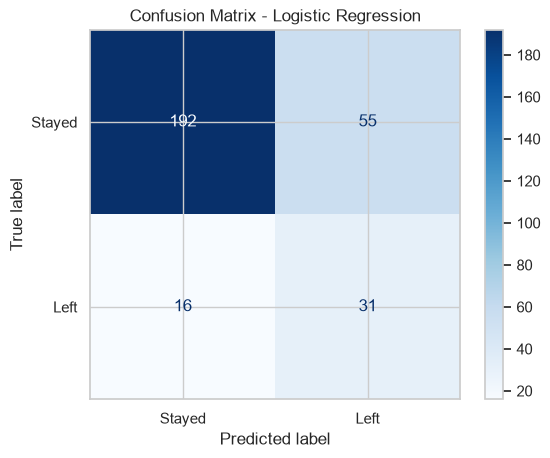

In [17]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

disp.plot(cmap="Blues")

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

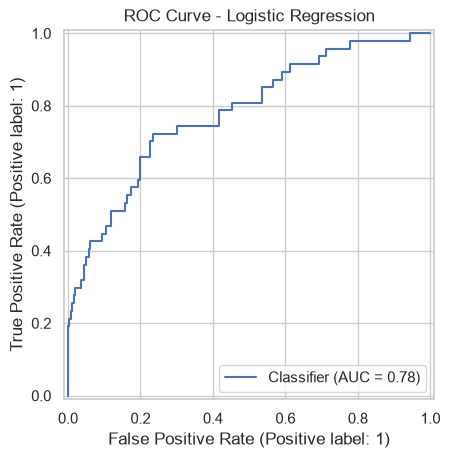

ROC-AUC Score: 0.7807


In [18]:
RocCurveDisplay.from_predictions(
    y_test,
    best_probabilities
)

plt.title(f"ROC Curve - {best_model_name}")
plt.show()

print(
    "ROC-AUC Score:",
    round(roc_auc_score(y_test, best_probabilities), 4)
)

Top 15 Important Features:


,Feature,Importance
16,OverTime,0.101542
13,MonthlyIncome,0.039142
15,NumCompaniesWorked,0.029804
20,StockOptionLevel,0.025635
1,BusinessTravel,0.016935
25,YearsInCurrentRole,0.012025
27,YearsWithCurrManager,0.011370
22,TrainingTimesLastYear,0.010733
29,PromotionDelay,0.010578
30,EngagementScore,0.010216


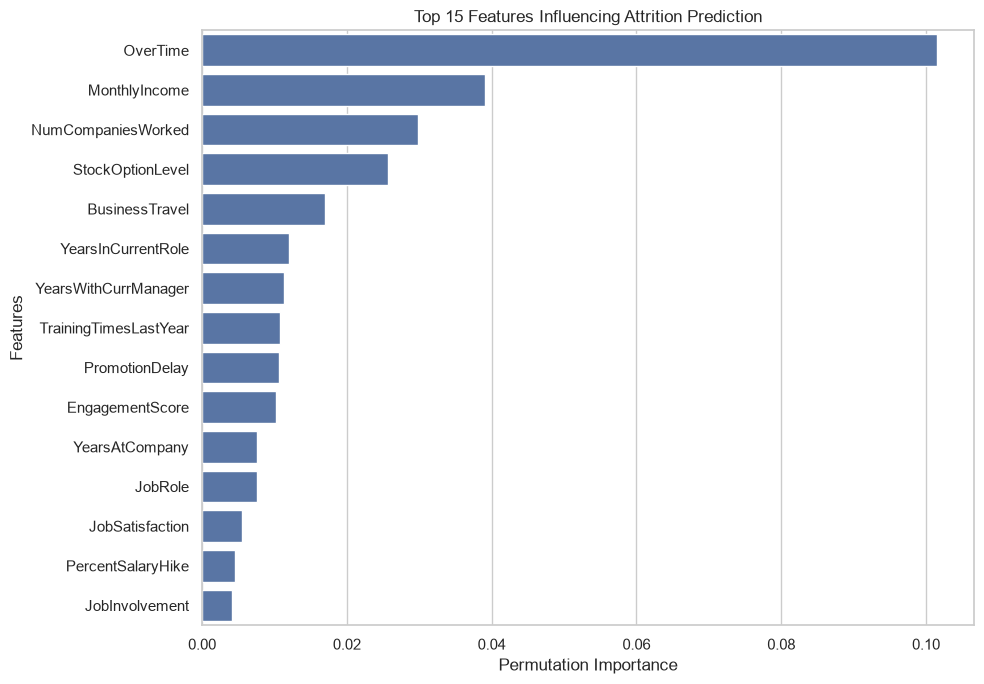

In [19]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Attrition Prediction")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

importance_df.to_csv(
    REPORT_DIR / "feature_importance.csv",
    index=False
)

In [20]:
# Predict risk scores for all employees

employee_probabilities = best_model.predict_proba(X)[:, 1]

risk_df = processed_df.copy()

risk_df["AttritionRiskScore"] = employee_probabilities * 100

risk_df["RiskCategory"] = np.select(
    [
        risk_df["AttritionRiskScore"] < 30,
        risk_df["AttritionRiskScore"] <= 60
    ],
    [
        "Low Risk",
        "Medium Risk"
    ],
    default="High Risk"
)

print("Employee Risk Scoring Completed!")

display(
    risk_df[
        [
            "Age",
            "Department",
            "JobRole",
            "Attrition",
            "AttritionRiskScore",
            "RiskCategory"
        ]
    ].head(10)
)

Employee Risk Scoring Completed!


,Age,Department,JobRole,Attrition,AttritionRiskScore,RiskCategory
0,41,Sales,Sales Executive,1,89.793053,High Risk
1,49,Research & Development,Research Scientist,0,7.984550,Low Risk
2,37,Research & Development,Laboratory Technician,1,61.051546,High Risk
3,33,Research & Development,Research Scientist,0,62.530647,High Risk
4,27,Research & Development,Laboratory Technician,0,77.212644,High Risk
5,32,Research & Development,Laboratory Technician,0,28.163555,Low Risk
6,59,Research & Development,Laboratory Technician,0,37.656708,Medium Risk
7,30,Research & Development,Laboratory Technician,0,53.752832,Medium Risk
8,38,Research & Development,Manufacturing Director,0,20.039909,Low Risk
9,36,Research & Development,Healthcare Representative,0,14.284739,Low Risk


Employee Risk Distribution:


RiskCategory
Low Risk       753
Medium Risk    378
High Risk      339
Name: count, dtype: int64

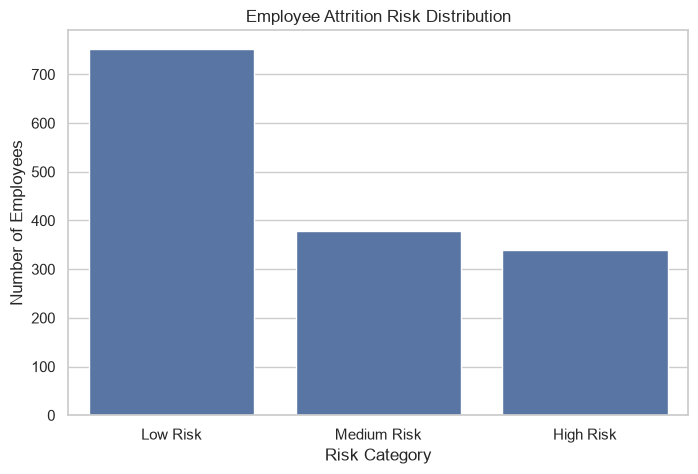

In [21]:
risk_counts = risk_df["RiskCategory"].value_counts()

print("Employee Risk Distribution:")
display(risk_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_df,
    x="RiskCategory",
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Employee Attrition Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Employees")
plt.show()

Department-wise Risk Analysis:


,TotalEmployees,ActualAttritionRate,AverageRiskScore,HighRiskEmployees
Department,,,,
Human Resources,63,19.05,38.61,14
Research & Development,961,13.84,31.00,178
Sales,446,20.63,44.79,147


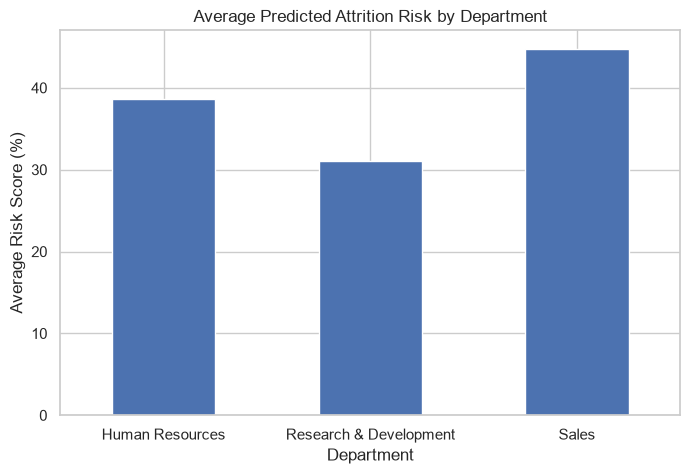

In [22]:
department_risk = (
    risk_df.groupby("Department")
    .agg(
        TotalEmployees=("Department", "count"),
        ActualAttritionRate=("Attrition", "mean"),
        AverageRiskScore=("AttritionRiskScore", "mean"),
        HighRiskEmployees=(
            "RiskCategory",
            lambda x: (x == "High Risk").sum()
        )
    )
)

department_risk["ActualAttritionRate"] *= 100

print("Department-wise Risk Analysis:")
display(department_risk.round(2))

department_risk["AverageRiskScore"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Predicted Attrition Risk by Department")
plt.xlabel("Department")
plt.ylabel("Average Risk Score (%)")
plt.xticks(rotation=0)
plt.show()

In [23]:
high_risk_employees = risk_df[
    risk_df["RiskCategory"] == "High Risk"
].copy()

high_risk_employees = high_risk_employees.sort_values(
    by="AttritionRiskScore",
    ascending=False
)

print("Total High-Risk Employees:", len(high_risk_employees))

display(
    high_risk_employees[
        [
            "Age",
            "Department",
            "JobRole",
            "OverTime",
            "JobSatisfaction",
            "WorkLifeBalance",
            "AttritionRiskScore"
        ]
    ].head(20)
)

Total High-Risk Employees: 339


,Age,Department,JobRole,OverTime,JobSatisfaction,WorkLifeBalance,AttritionRiskScore
457,18,Sales,Sales Representative,Yes,2,3,99.163933
463,26,Research & Development,Laboratory Technician,Yes,4,1,99.098691
357,21,Sales,Sales Representative,Yes,2,3,98.800967
1060,24,Research & Development,Laboratory Technician,Yes,1,2,98.687847
1153,18,Sales,Sales Representative,Yes,4,4,98.394254
1057,29,Sales,Sales Executive,No,2,1,98.307307
1379,27,Human Resources,Human Resources,No,2,3,98.281475
656,32,Research & Development,Laboratory Technician,Yes,4,1,98.074292
127,19,Sales,Sales Representative,Yes,3,2,98.068018
911,25,Sales,Sales Representative,Yes,4,3,97.534964


In [24]:
# Select an employee from the test dataset

employee_number = 0

employee = X_test.iloc[[employee_number]]

actual_status = y_test.iloc[employee_number]

predicted_probability = best_model.predict_proba(employee)[0][1]

risk_score = predicted_probability * 100

if risk_score < 30:
    risk_category = "Low Risk"
elif risk_score <= 60:
    risk_category = "Medium Risk"
else:
    risk_category = "High Risk"

print("EMPLOYEE ATTRITION PREDICTION")
print("--------------------------------")
print("Actual Attrition Status:", actual_status)
print("Predicted Risk Score:", round(risk_score, 2), "%")
print("Risk Category:", risk_category)

EMPLOYEE ATTRITION PREDICTION
--------------------------------
Actual Attrition Status: 0
Predicted Risk Score: 41.49 %
Risk Category: Medium Risk


In [25]:
# Save the complete trained pipeline

model_path = MODEL_DIR / "attrition_model.pkl"

model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "features": X.columns.tolist(),
    "metrics": results_df.iloc[0].to_dict(),
    "risk_thresholds": {
        "low": 30,
        "high": 60
    }
}

joblib.dump(model_bundle, model_path)

# Save employee risk scores
risk_df.to_csv(
    REPORT_DIR / "employee_risk_scores.csv",
    index=False
)

# Save test predictions
test_predictions = X_test.copy()

test_predictions["ActualAttrition"] = y_test.values
test_predictions["PredictedAttrition"] = best_predictions
test_predictions["PredictedRiskScore"] = best_probabilities * 100

test_predictions.to_csv(
    REPORT_DIR / "test_predictions.csv",
    index=False
)

print("Model and reports saved successfully!")
print("Model Location:", model_path)

Model and reports saved successfully!
Model Location: c:\Users\91785\OneDrive\Desktop\employee-attrition-prediction\models\attrition_model.pkl


In [26]:
total_employees = len(risk_df)

employees_left = int(risk_df["Attrition"].sum())

actual_attrition_rate = (
    employees_left / total_employees
) * 100

high_risk_count = int(
    (risk_df["RiskCategory"] == "High Risk").sum()
)

print("=" * 50)
print("EMPLOYEE ATTRITION ANALYTICS - PROJECT SUMMARY")
print("=" * 50)

print("Total Employees:", total_employees)
print("Employees Who Left:", employees_left)
print("Actual Attrition Rate:", round(actual_attrition_rate, 2), "%")
print("High Risk Employees:", high_risk_count)

print("\nBest Machine Learning Model:", best_model_name)

print("\nModel Performance:")
display(results_df.iloc[0:1])


EMPLOYEE ATTRITION ANALYTICS - PROJECT SUMMARY
Total Employees: 1470
Employees Who Left: 237
Actual Attrition Rate: 16.12 %
High Risk Employees: 339

Best Machine Learning Model: Logistic Regression

Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.758503,0.360465,0.659574,0.466165,0.780687
